# Modelo Paramétrico: Ridge Regression

## Introducción
Este notebook desarrolla un modelo **Ridge Regression** para estimar el volumen de compras recientes de productos de Amazon.

La variable objetivo es `bought_in_last_month`. Debido a su asimetría, se modelará su transformación `log_bought = log1p(bought_in_last_month)`. Las predicciones se transformarán nuevamente a la escala original para facilitar su interpretación.

## Objetivos del modelo

- Construir un modelo Ridge para predecir las compras recientes.
- Seleccionar la regularización L2 mediante validación cruzada de cinco folds.
- Mantener el preprocesamiento dentro del pipeline para ajustarlo independientemente en cada fold y evitar fuga de información durante la validación.
- Reservar el conjunto de prueba para una única evaluación final.
- Evaluar el modelo en escala logarítmica y en la escala original de compras.
- Exportar el modelo, las métricas, la búsqueda CV y las predicciones para reproducibilidad.

## Carga de librerías
Se importan las herramientas para manipulación de datos, preprocesamiento, modelado, evaluación, visualización y exportación.

In [ ]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_squared_log_error
)
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
print("Librerías cargadas correctamente.")

## Configuración inicial
Se fijan las rutas, el estado aleatorio y los nombres de las variables. Ajusta `DATA_PATH` si el archivo tiene otra ubicación en Google Drive o Colab.

In [33]:
RANDOM_STATE = 0
DATASET_FILENAME = "dataset_v4.csv"
TARGET = "log_bought"
ORIGINAL_TARGET = "bought_in_last_month"
STRATIFY_COLUMN = "bought_cat"
OUTPUT_DIR = Path("../Modelos entrenados/Models_Results/results_ridge")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_DIR = Path("Models_Results") / "results_ridge"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

NUMERIC_FEATURES = [
    "Rating",
    "log_reviews",
    "log_price",
    "log_title_words",
    "has_discount",
    "is_best_seller_flag",
    "is_sponsored_flag",
    "has_coupon",
    "is_free_delivery",
    "is_price_outlier",
    "has_sustainability_badge",
]

DATA_CANDIDATES = [
    Path(DATASET_FILENAME),
    Path("Limpieza de datos") / DATASET_FILENAME,
    Path("/content") / DATASET_FILENAME,
    Path("/content/Limpieza de datos") / DATASET_FILENAME,
    Path("../Limpieza de datos") / DATASET_FILENAME,
]

SPLIT_CANDIDATES = [
    Path("results/random_forest/split_indices.json"),
    Path("../Models_Results/random_forest/split_indices.json"),
    Path("results_random_forest/split_indices.json"),
    Path("Modelos entrenados/results/random_forest/split_indices.json"),
    Path("split_indices.json"),
]

CATEGORICAL_FEATURES = ["buy_box_status"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print("Directorio de trabajo:", Path.cwd())
print("Directorio de resultados:", OUTPUT_DIR.resolve())

Directorio de trabajo: c:\Users\Juan Mona\Documents\Repositories\ProductScope-ML\Modelos entrenados
Directorio de resultados: C:\Users\Juan Mona\Documents\Repositories\ProductScope-ML\Modelos entrenados\Models_Results\results_ridge


## Carga de datos
Se carga el archivo v4. Si trabajas en Colab y el CSV está en otra ubicación, modifica `DATA_PATH` o utiliza el selector de archivos.

In [34]:
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    
except Exception:
    print("Entorno distinto de Colab o Drive no disponible.")

if not DATA_PATH.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("No se encontró un archivo CSV en la carga.")
        DATA_PATH = Path(csv_names[0])
    except ImportError:
        raise FileNotFoundError(
            f"No se encontró el CSV en {DATA_PATH}. Actualiza DATA_PATH."
        )

df = pd.read_csv(DATA_PATH)
print("Dimensiones:", df.shape)
display(df.head())

Entorno distinto de Colab o Drive no disponible.
Dimensiones: (31202, 18)


,Rating,Number_of_reviews,has_discount,is_best_seller_flag,is_sponsored_flag,has_coupon,buy_box_status,is_free_delivery,title_word_count,has_sustainability_badge,bought_in_last_month,bought_cat,current_price,is_price_outlier,log_price,log_reviews,log_bought,log_title_words
0,4.6,375.0,1,0,1,1,add_to_cart,0,30,1,350.0,201-500,89.68,0,4.507337,5.929589,5.860786,3.433987
1,4.3,2457.0,1,0,1,0,add_to_cart,0,34,0,6500.0,>500,9.99,0,2.396986,7.807103,8.779711,3.555348
2,4.6,3044.0,1,0,1,0,add_to_cart,0,29,0,2500.0,>500,314.00,1,5.752573,8.021256,7.824446,3.401197
3,4.6,35882.0,0,1,0,0,unknown,0,24,0,15000.0,>500,71.89,0,4.288951,10.488019,9.615872,3.218876
4,4.8,28988.0,0,0,0,0,unknown,0,24,0,15000.0,>500,71.89,0,4.288951,10.274672,9.615872,3.218876


## Exploración y validación
Se comprueba la presencia de las columnas requeridas, la disponibilidad del objetivo y la distribución de compras. `bought_cat` se reserva exclusivamente para estratificar las particiones; no será una característica del modelo.

In [35]:
required_columns = FEATURES + [TARGET, ORIGINAL_TARGET, STRATIFY_COLUMN]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas en el CSV v4: {missing_columns}")

df = df.dropna(subset=[TARGET, ORIGINAL_TARGET, STRATIFY_COLUMN]).copy()
df[STRATIFY_COLUMN] = df[STRATIFY_COLUMN].astype(str)

print("Registros válidos:", len(df))
print("\nDistribución del objetivo original:")
display(df[ORIGINAL_TARGET].describe())
print("\nFrecuencia de categorías de estratificación:")
display(df[STRATIFY_COLUMN].value_counts().sort_index())

Registros válidos: 31202

Distribución del objetivo original:


count     31202.000000
mean       1171.992981
std        5944.714780
min          75.000000
25%         150.000000
50%         250.000000
75%         450.000000
max      150000.000000
Name: bought_in_last_month, dtype: float64


Frecuencia de categorías de estratificación:


bought_cat
101-200    8801
201-500    9879
50-100     5967
>500       6555
Name: count, dtype: int64

## Selección de características
Se emplean las mismas características iniciales definidas para los otros modelos. Se excluyen el objetivo, su transformación y `bought_cat` para evitar fuga de información. En el dataset v4 no se incluye `delivery_cost`.

In [36]:
X = df[FEATURES].copy()
y = df[TARGET].astype(float).copy()
y_original = df[ORIGINAL_TARGET].astype(float).copy()
strat = df[STRATIFY_COLUMN].astype(str).copy()

assert TARGET not in X.columns
assert ORIGINAL_TARGET not in X.columns
assert STRATIFY_COLUMN not in X.columns

print("Características numéricas:", NUMERIC_FEATURES)
print("Características categóricas:", CATEGORICAL_FEATURES)
print("Matriz X:", X.shape)

Características numéricas: ['Rating', 'log_reviews', 'log_price', 'log_title_words', 'has_discount', 'is_best_seller_flag', 'is_sponsored_flag', 'has_coupon', 'is_free_delivery', 'is_price_outlier', 'has_sustainability_badge']
Características categóricas: ['buy_box_status']
Matriz X: (31202, 12)


## Preprocesamiento
Las variables numéricas se imputan con la mediana y se estandarizan, algo importante para Ridge porque la penalización depende de la magnitud de los coeficientes. La variable categórica se imputa con la categoría más frecuente y se codifica mediante One-Hot Encoding. Todo el preprocesamiento se ajusta dentro del pipeline usando únicamente los datos de entrenamiento.

In [38]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, NUMERIC_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES)
])
print("Preprocesador definido.")

Preprocesador definido.


## División de datos

Se conserva una partición estratificada 70% entrenamiento, 15% validación y 15% prueba. La validación se incorpora al conjunto de desarrollo para seleccionar `alpha` mediante validación cruzada de cinco folds. El conjunto de prueba queda aislado hasta la evaluación final. Si existe `split_indices.json`, se reutilizan sus índices para reproducibilidad.

In [54]:
SPLIT_CANDIDATES = [
    Path("../Modelos entrenados/Models_Results/results_ridge/split_indices.json"),
    Path("results/range/split_indices.json"),
    Path("results_ridge/split_indices.json"),
    Path("Modelos entrenados/results/range/split_indices.json"),
    Path("split_indices.json"),
]

split_path = next((path for path in SPLIT_CANDIDATES if path.exists()), None)

if split_path is not None and split_path.exists():
    with open(split_path, "r", encoding="utf-8") as f:
        split_data = json.load(f)

    # Los índices exportados deben corresponder al índice original del CSV.
    original_indices = df.index
    train_idx = pd.Index(split_data["train"])
    val_idx = pd.Index(split_data["validation"])
    test_idx = pd.Index(split_data["test"])

    if not (train_idx.isin(original_indices).all()
            and val_idx.isin(original_indices).all()
            and test_idx.isin(original_indices).all()):
        raise ValueError(
            "Los índices guardados no coinciden con el CSV cargado. "
            "Comprueba que utilizas exactamente el mismo archivo y orden de filas."
        )

    train_mask = df.index.isin(train_idx)
    val_mask = df.index.isin(val_idx)
    test_mask = df.index.isin(test_idx)

    X_train, y_train = X.loc[train_mask], y.loc[train_mask]
    X_val, y_val = X.loc[val_mask], y.loc[val_mask]
    X_test, y_test = X.loc[test_mask], y.loc[test_mask]
    y_train_original = y_original.loc[train_mask]
    y_val_original = y_original.loc[val_mask]
    y_test_original = y_original.loc[test_mask]

else:
    X_temp, X_test, y_temp, y_test, strat_temp, strat_test = train_test_split(
        X, y, strat, test_size=0.15, random_state=RANDOM_STATE, stratify=strat
    )
    y_original_temp = y_original.loc[X_temp.index]
    y_test_original = y_original.loc[X_test.index]

    X_train, X_val, y_train, y_val, strat_train, strat_val = train_test_split(
        X_temp, y_temp, strat_temp, test_size=(0.15 / 0.85),
        random_state=RANDOM_STATE, stratify=strat_temp
    )
    y_train_original = y_original.loc[X_train.index]
    y_val_original = y_original.loc[X_val.index]

    split_data = {
        "train": X_train.index.tolist(),
        "validation": X_val.index.tolist(),
        "test": X_test.index.tolist()
    }

    Path("../Modelos entrenados/Models_Results/results_ridge").mkdir(exist_ok=True)
    with open("../Modelos entrenados/Models_Results/results_ridge/split_indices.json", "w", encoding="utf-8") as f:
        json.dump(split_data, f)

print("Tamaños:", len(X_train), len(X_val), len(X_test))
print("Proporciones:", np.array([len(X_train), len(X_val), len(X_test)]) / len(df))

Tamaños: 21840 4681 4681
Proporciones: [0.69995513 0.15002243 0.15002243]


## Construcción del modelo
Se define un pipeline que integra el preprocesamiento y Ridge Regression. `alpha` controla la intensidad de la regularización L2: valores mayores penalizan más los coeficientes.

In [55]:
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

print(ridge_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating', 'log_reviews',
                                                   'log_price',
                                                   'log_title_words',
                                                   'has_discount',
                                                   'is_best_seller_flag',
                                                   'is_sponsored_flag',
                                                   'has_coupon',
                                                   'is_free_delivery',
      

## Entrenamiento del modelo base
Se entrena una configuración inicial con `alpha=1.0`. Este resultado sirve como referencia antes de optimizar el hiperparámetro.

In [56]:
ridge_pipeline.set_params(model__alpha=1.0)
ridge_pipeline.fit(X_train, y_train)

val_pred_base = ridge_pipeline.predict(X_val)
base_rmse = mean_squared_error(y_val, val_pred_base) ** 0.5
print(f"RMSE de validación (alpha=1.0): {base_rmse:.5f}")

RMSE de validación (alpha=1.0): 0.85794


## Optimización de hiperparámetros mediante validación cruzada

La selección de `alpha` se realiza con `GridSearchCV` y validación cruzada K-Fold de cinco particiones sobre el conjunto de desarrollo (entrenamiento + validación). Se amplía la rejilla desde `10^-8` hasta `10^4`, porque la búsqueda anterior seleccionaba el límite inferior (`10^-4`). La métrica de selección es RMSE en escala logarítmica.

El preprocesador forma parte del `Pipeline`; por ello, imputación, escalado y One-Hot Encoding se ajustan de nuevo dentro de cada fold. El conjunto de prueba no interviene en la selección de hiperparámetros.

In [ ]:
# El conjunto de validación se incorpora al conjunto de desarrollo.
# El test permanece separado y no participa en la selección de alpha.
X_train_val = pd.concat([X_train, X_val], axis=0).sort_index()
y_train_val = pd.concat([y_train, y_val], axis=0).sort_index()

alpha_values = np.logspace(-8, 4, 49)

ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

cv_splitter = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=cv_splitter,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

ridge_search.fit(X_train_val, y_train_val)

best_alpha = float(ridge_search.best_params_["model__alpha"])
best_cv_rmse = float(-ridge_search.best_score_)
final_model = ridge_search.best_estimator_

cv_results = pd.DataFrame(ridge_search.cv_results_)[[
    "param_model__alpha",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "rank_test_score"
]].copy()

cv_results = cv_results.rename(columns={
    "param_model__alpha": "alpha",
    "mean_test_score": "mean_cv_rmse_log_negative",
    "std_test_score": "std_cv_rmse_log",
    "mean_train_score": "mean_train_score_negative",
    "rank_test_score": "rank"
})
cv_results["mean_cv_rmse_log"] = -cv_results["mean_cv_rmse_log_negative"]
cv_results["mean_train_rmse_log"] = -cv_results["mean_train_score_negative"]
cv_results = cv_results.drop(columns=[
    "mean_cv_rmse_log_negative",
    "mean_train_score_negative"
]).sort_values("rank")

display(cv_results.head(10))
print(f"Mejor alpha: {best_alpha:.8g}")
print(f"RMSE CV (log): {best_cv_rmse:.5f}")

cv_results.to_csv(OUTPUT_DIR / "cross_validation_results.csv", index=False)

with open(OUTPUT_DIR / "best_hyperparameters.json", "w", encoding="utf-8") as f:
    json.dump({
        "model": "Ridge",
        "best_alpha": best_alpha,
        "cv": "KFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": RANDOM_STATE,
        "scoring": "neg_root_mean_squared_error",
        "best_cv_rmse_log": best_cv_rmse,
        "alpha_grid_min": float(alpha_values.min()),
        "alpha_grid_max": float(alpha_values.max()),
        "alpha_grid_size": int(len(alpha_values))
    }, f, indent=4)

## Evaluación final

`GridSearchCV` selecciona `alpha` mediante validación cruzada en el conjunto de desarrollo y reajusta automáticamente el mejor pipeline con todos sus registros (`refit=True`). El conjunto de prueba se utiliza una sola vez para estimar el rendimiento final. No se modifica ni se consulta durante la selección de hiperparámetros.

In [ ]:
# GridSearchCV ya ha reajustado el mejor pipeline con todo el conjunto de desarrollo.
# No se vuelve a ajustar con el conjunto de prueba.
pred_test_log = final_model.predict(X_test)
pred_test_original = np.maximum(0, np.expm1(pred_test_log))
y_test_original_array = y_test_original.to_numpy()
pred_test_original = np.maximum(0, pred_test_original)

metrics = {
    "MAE_log": float(mean_absolute_error(y_test, pred_test_log)),
    "RMSE_log": float(mean_squared_error(y_test, pred_test_log) ** 0.5),
    "R2_log": float(r2_score(y_test, pred_test_log)),
    "MAE_original": float(mean_absolute_error(y_test_original_array, pred_test_original)),
    "RMSE_original": float(mean_squared_error(y_test_original_array, pred_test_original) ** 0.5),
    "R2_original": float(r2_score(y_test_original_array, pred_test_original)),
    "RMSLE_original": float(mean_squared_log_error(
        y_test_original_array, pred_test_original
    ) ** 0.5),
    "best_alpha": best_alpha,
    "cv_strategy": "KFold",
    "cv_n_splits": 5,
    "cv_rmse_log": best_cv_rmse,
    "development_train_rows": int(len(X_train_val)),
    "test_rows": int(len(X_test))
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "Ridge"}))
with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

## Visualización de resultados
Se comparan valores reales y predichos en la escala original y se inspecciona la distribución de residuos. Estas visualizaciones ayudan a identificar sesgos sistemáticos y errores grandes.

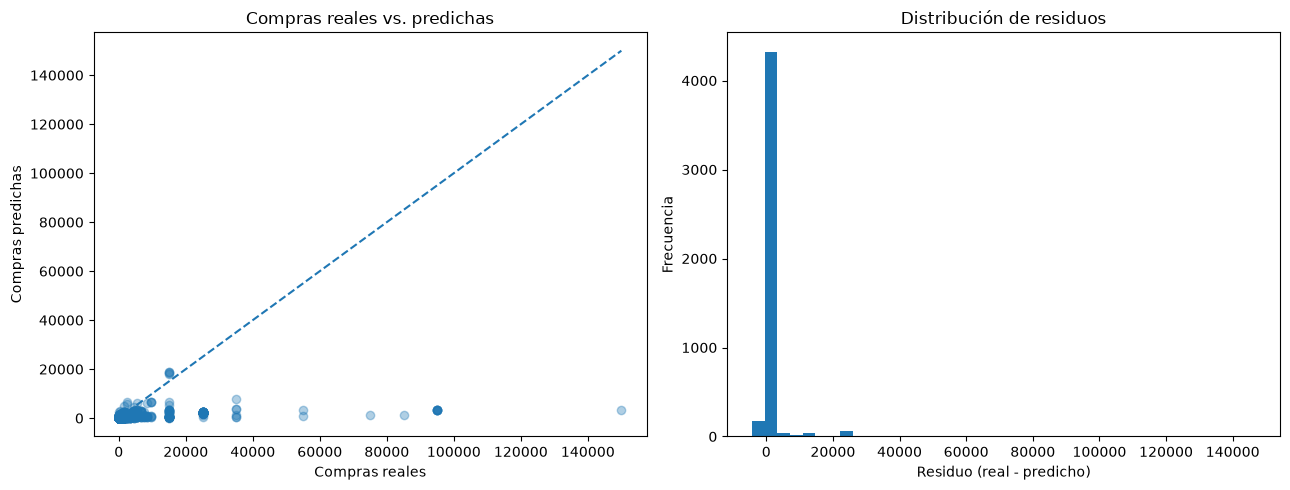

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test_original_array, pred_test_original, alpha=0.35)
max_value = max(y_test_original_array.max(), pred_test_original.max())
axes[0].plot([0, max_value], [0, max_value], linestyle="--")
axes[0].set_title("Compras reales vs. predichas")
axes[0].set_xlabel("Compras reales")
axes[0].set_ylabel("Compras predichas")

residuals = y_test_original_array - pred_test_original
axes[1].hist(residuals, bins=40)
axes[1].set_title("Distribución de residuos")
axes[1].set_xlabel("Residuo (real - predicho)")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

## Análisis e interpretación

Interpreta el rendimiento usando las métricas calculadas sobre el conjunto de prueba y el RMSE promedio de validación cruzada. Compara la dispersión entre folds (`std_cv_rmse_log`) para valorar la estabilidad de la selección de `alpha`. No anticipes conclusiones hasta ejecutar el notebook con el dataset correspondiente.

Si el mejor `alpha` vuelve a ubicarse en uno de los extremos de la rejilla, amplía el rango en esa dirección y repite la búsqueda sin consultar el test.

In [60]:
print(f"Alpha seleccionado: {best_alpha:.6g}")
print(f"RMSE log: {metrics['RMSE_log']:.4f}")
print(f"R² log: {metrics['R2_log']:.4f}")
print(f"MAE original: {metrics['MAE_original']:.4f}")
print(f"RMSE original: {metrics['RMSE_original']:.4f}")
print(f"RMSLE original: {metrics['RMSLE_original']:.4f}")

Alpha seleccionado: 0.0001
RMSE log: 0.8776
R² log: 0.4800
MAE original: 990.8811
RMSE original: 5661.9501
RMSLE original: 0.8776


## Exportación de resultados

Se guardan el pipeline final reajustado por `GridSearchCV`, las métricas del test, los hiperparámetros seleccionados, los resultados por fold y las predicciones. Estos artefactos permiten reproducir la selección del modelo y su evaluación final.

In [ ]:
joblib.dump(final_model, OUTPUT_DIR / "ridge_final.joblib")

predictions_df = pd.DataFrame({
    "row_index": X_test.index,
    "actual_bought": y_test_original_array,
    "predicted_bought": pred_test_original,
    "actual_log_bought": y_test.to_numpy(),
    "predicted_log_bought": pred_test_log
})
predictions_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

print("Archivos exportados en:", OUTPUT_DIR.resolve())
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)